# Agregação de famílias de inicialização com os quatro métodos finais

Os notebooks 01–03 testaram cada forma de histórico inicial isoladamente: zero,
constantes, uniforme (ruído branco), cosseno e estacionária conjunta. Este notebook
testa a nova inicialização do gerador de treino (`RandomHistorySpec`): para cada canal,
cada família (**constante**, **ruído branco** e **cosseno**) aparece ou não de forma
independente, seus parâmetros são sorteados e os componentes presentes são **somados**.

Usa o mesmo banco determinístico de mecanismos e as mesmas sementes de trajetória dos
notebooks 01–03 (AST original, Jacobiana, Shao–Wu e Heaps). A estacionária conjunta não
é uma família: ela existe apenas para Heaps.

In [1]:
from dataclasses import asdict
from itertools import combinations
from pathlib import Path
import hashlib
import importlib.metadata
import json
import platform
import subprocess
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next(p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
            if (p / "src" / "tsfmxai").exists())
sys.path.insert(0, str(ROOT / "src"))
from tsfmxai.evaluation.initialization import (
    GROUPS, InitializationStudyConfig, run_history_case, sample_study_mechanisms,
)
from tsfmxai.generators.initialization import (
    FAMILIES, RandomHistorySpec, random_history_bound, sample_random_history,
)

CONFIG = InitializationStudyConfig(mechanisms=32, trajectories=3,
                                   mechanism_seed=2026111001, trajectory_seed=2026111002,
                                   innovation_std=.05, example_mechanisms=0)
assert GROUPS == ("Original AST", "Jacobian", "Shao-Wu", "Heaps")
BANKS = {group: sample_study_mechanisms(group, CONFIG) for group in GROUPS}
assert all(len(bank) == CONFIG.mechanisms for bank in BANKS.values())
print("Mechanism bank:", {group: len(bank) for group, bank in BANKS.items()})

LABELS = {"constant": "constante", "noise": "ruído branco", "cosine": "cosseno"}
COLORS = {"constant": "#b8901a", "noise": "#4488a3", "cosine": "#c4526b", "sum": "#1f2a24"}
# Two interval regimes. The default lets each family reach magnitude 1 (sum up to 3,
# outside the Jacobian certified box of radius 1). The unit-box regime divides every
# maximum by 3 so that any sum stays inside the box and the Jacobian can be evaluated.
RANGES = {
    "padrão": dict(constant_magnitude=(0., 1.), noise_radius=(.1, 1.),
                   cosine_amplitude=(.1, 1.), cosine_period=(4, 48)),
    "caixa unitária": dict(constant_magnitude=(0., 1 / 3), noise_radius=(.1 / 3, 1 / 3),
                           cosine_amplitude=(.1 / 3, 1 / 3), cosine_period=(4, 48)),
}
SUBSETS = [()] + [c for r in (1, 2, 3) for c in combinations(FAMILIES, r)]

def subset_name(present):
    return " + ".join(LABELS[f] for f in present) if present else "zero (nenhuma)"

def subset_spec(present, ranges):
    return RandomHistorySpec(subset_name(present), **ranges,
                             **{f"{f}_probability": float(f in present) for f in FAMILIES})

MIXTURE = "sorteio (p = 0,5 cada)"
SPECS = {regime: [subset_spec(s, ranges) for s in SUBSETS]
                 + [RandomHistorySpec(MIXTURE, **ranges)]
         for regime, ranges in RANGES.items()}
display(pd.DataFrame([(regime, s.name, random_history_bound(s)) for regime, specs in SPECS.items()
                      for s in specs], columns=["regime", "caso", "cota de |histórico|"]))

Mechanism bank: {'Original AST': 32, 'Jacobian': 32, 'Shao-Wu': 32, 'Heaps': 32}


,regime,caso,cota de |histórico|
0,padrão,zero (nenhuma),0.000000
1,padrão,constante,1.000000
2,padrão,ruído branco,1.000000
3,padrão,cosseno,1.000000
4,padrão,constante + ruído branco,2.000000
5,padrão,constante + cosseno,2.000000
6,padrão,ruído branco + cosseno,2.000000
7,padrão,constante + ruído branco + cosseno,3.000000
8,padrão,"sorteio (p = 0,5 cada)",3.000000
9,caixa unitária,zero (nenhuma),0.000000


## Como as famílias se somam

Cada família tem uma forma própria:

| Família | Componente | Parâmetros sorteados (regime padrão) |
|---|---|---|
| constante | `s·m` | sinal ±, `m ~ U(0, 1)` |
| ruído branco | `U(−r, r)` i.i.d. por lag | `r ~ U(0,1; 1)` |
| cosseno | `A·cos(2πk/T + φ)` | `A ~ U(0,1; 1)`, `T ~ U{4..48}`, `φ ~ U(0, 2π)` |

A figura abaixo decompõe um histórico com as três famílias presentes. O comprimento é
16, o maior lag do gerador de treino: é o histórico real que dispara a recorrência.

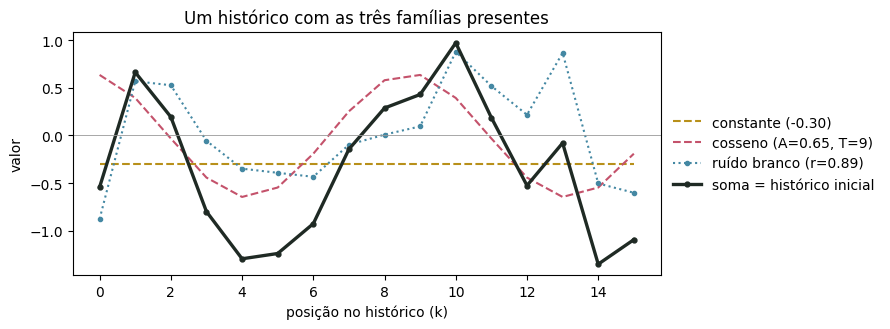

In [2]:
LENGTH = 16
k = np.arange(LENGTH)
all_three = subset_spec(FAMILIES, RANGES["padrão"])
history, components = sample_random_history(all_three, 1, LENGTH, np.random.default_rng(7))
parts = {p["family"]: p for p in components[0]}
level = np.full(LENGTH, parts["constant"]["level"])
wave = parts["cosine"]["amplitude"] * np.cos(2 * np.pi * k / parts["cosine"]["period"] + parts["cosine"]["phase"])
noise = history[0] - level - wave
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.plot(k, level, color=COLORS["constant"], ls="--", label=f"constante ({parts['constant']['level']:+.2f})")
ax.plot(k, wave, color=COLORS["cosine"], ls="--",
        label=f"cosseno (A={parts['cosine']['amplitude']:.2f}, T={parts['cosine']['period']})")
ax.plot(k, noise, color=COLORS["noise"], ls=":", marker=".", label=f"ruído branco (r={parts['noise']['radius']:.2f})")
ax.plot(k, history[0], color=COLORS["sum"], lw=2.4, marker="o", ms=3.5, label="soma = histórico inicial")
ax.axhline(0, color="#999", lw=.6)
ax.set_xlabel("posição no histórico (k)"); ax.set_ylabel("valor")
ax.set_title("Um histórico com as três famílias presentes")
ax.legend(loc="center left", bbox_to_anchor=(1, .5), frameon=False)
fig.tight_layout(); plt.show()

## Todas as combinações

Cada painel fixa quais famílias aparecem e mostra quatro sorteios dos parâmetros. Com
a ordem de sorteio fixa, o mesmo índice de sorteio usa os mesmos parâmetros em todos os
painéis: só muda quais componentes entram na soma.

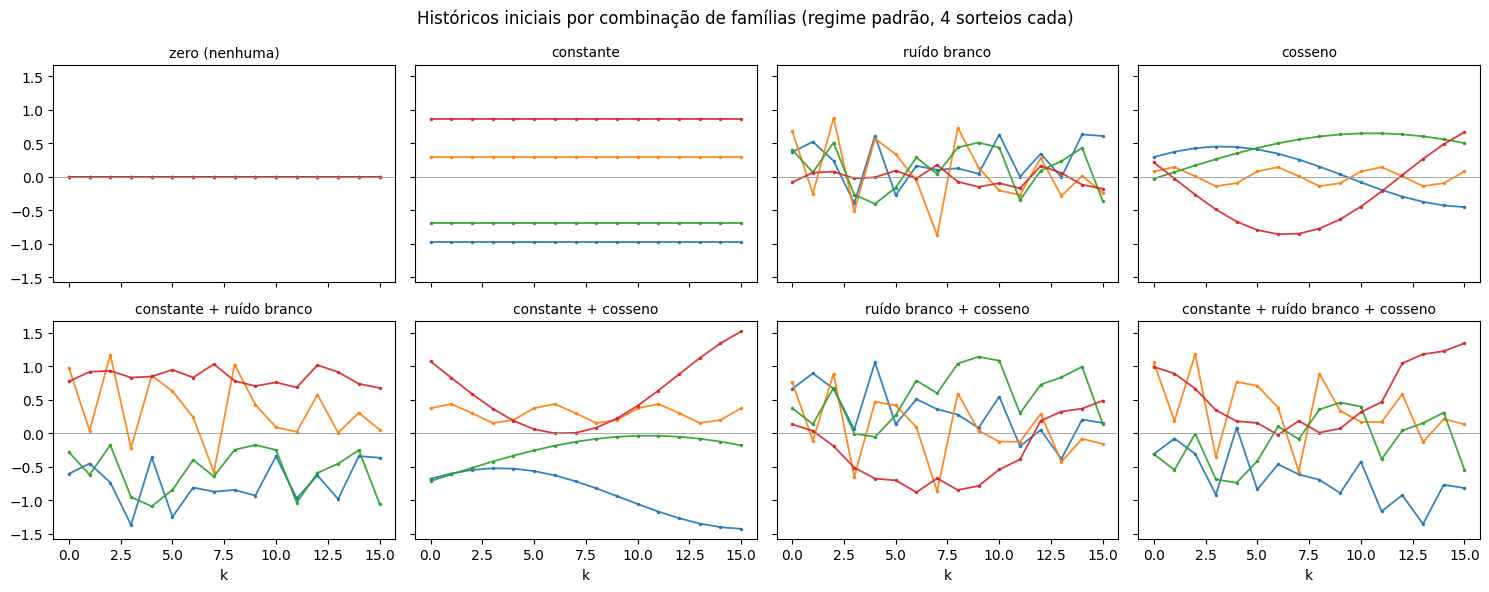

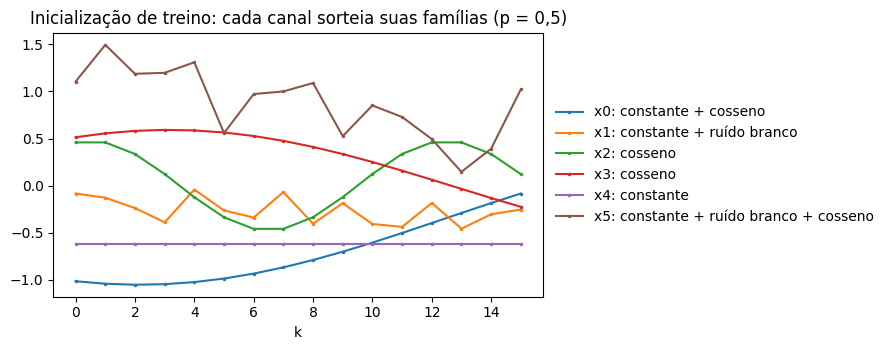

In [3]:
fig, axes = plt.subplots(2, 4, figsize=(15, 6), sharex=True, sharey=True)
for ax, present in zip(axes.ravel(), SUBSETS):
    spec = subset_spec(present, RANGES["padrão"])
    for draw in range(4):
        h, _ = sample_random_history(spec, 1, LENGTH, np.random.default_rng(100 + draw))
        ax.plot(k, h[0], marker=".", ms=3, lw=1.3, alpha=.9)
    ax.axhline(0, color="#999", lw=.6)
    ax.set_title(subset_name(present), fontsize=10)
for ax in axes[-1]:
    ax.set_xlabel("k")
fig.suptitle("Históricos iniciais por combinação de famílias (regime padrão, 4 sorteios cada)")
fig.tight_layout(); plt.show()

spec = RandomHistorySpec(MIXTURE, **RANGES["padrão"])
h, comps = sample_random_history(spec, 6, LENGTH, np.random.default_rng(2026))
fig, ax = plt.subplots(figsize=(9, 3.6))
for channel, (row, parts) in enumerate(zip(h, comps)):
    ax.plot(k, row, marker=".", ms=3, label=f"x{channel}: " + (" + ".join(LABELS[p["family"]] for p in parts) or "zero"))
ax.set_title("Inicialização de treino: cada canal sorteia suas famílias (p = 0,5)")
ax.set_xlabel("k"); ax.legend(loc="center left", bbox_to_anchor=(1, .5), frameon=False)
fig.tight_layout(); plt.show()

## Métricas por combinação

Mesmas métricas dos notebooks 01–03, nos horizontes 96, 192 e 384: explosão, quase zero,
cauda plana e queda de amplitude até zero. Cada caso tem 32 mecanismos × 3 trajetórias.
Os sorteios são pareados entre casos: a mesma trajetória usa as mesmas inovações e os
mesmos parâmetros de família em todas as combinações. Casos fora da caixa certificada da
Jacobiana são registrados como não executados, não como falhas.

In [4]:
rows, skipped = [], []
for regime, specs in SPECS.items():
    for spec in specs:
        for group in GROUPS:
            result = run_history_case(group, BANKS[group], CONFIG, spec)
            rows += [dict(row, regime=regime) for row in result["rows"]]
            skipped += [dict(item, regime=regime, bound=random_history_bound(spec)) for item in result["skipped"]]
rows = pd.DataFrame(rows)
CASES = [s.name for s in SPECS["padrão"]]
summary = rows.groupby(["regime", "method", "case", "horizon"], sort=False).agg(
    attempts=("exploded", "size"), explosions=("exploded", "sum"), near_zero=("near_zero", "sum"),
    flat_tail=("flat_tail", "sum"), amplitude_decline=("amplitude_decline_near_zero", "sum"),
    initial_max_abs_median=("initial_max_abs", "median"),
).reset_index()
for metric in ("explosions", "near_zero", "flat_tail", "amplitude_decline"):
    summary[f"{metric}_rate"] = summary[metric] / summary.attempts
assert summary.attempts.eq(CONFIG.mechanisms * CONFIG.trajectories).all()
skipped_blocks = (pd.DataFrame(skipped).groupby(["regime", "method", "case", "reason"], sort=False)
                  .agg(mechanisms=("mechanism", "nunique"), bound=("bound", "first")).reset_index())

def table(regime, metric, horizon=384):
    part = summary[summary.regime.eq(regime) & summary.horizon.eq(horizon)]
    pivot = part.pivot(index="case", columns="method", values=f"{metric}_rate").reindex(CASES)
    return pivot.reindex(columns=list(GROUPS)).map(lambda v: "—" if pd.isna(v) else f"{v:.0%}")

for regime in RANGES:
    for metric, title in (("explosions", "Explosão"), ("near_zero", "Quase zero"),
                          ("flat_tail", "Cauda plana"), ("amplitude_decline", "Queda de amplitude até zero")):
        print(f"{title} — regime {regime}, horizonte 384 (— = não executado)")
        display(table(regime, metric))
display(skipped_blocks)

Explosão — regime padrão, horizonte 384 (— = não executado)


method,Original AST,Jacobian,Shao-Wu,Heaps
case,,,,
zero (nenhuma),50%,0%,0%,0%
constante,53%,0%,0%,0%
ruído branco,50%,0%,0%,0%
cosseno,51%,0%,0%,0%
constante + ruído branco,53%,—,0%,0%
constante + cosseno,55%,—,0%,0%
ruído branco + cosseno,53%,—,0%,0%
constante + ruído branco + cosseno,56%,—,0%,0%
"sorteio (p = 0,5 cada)",51%,—,0%,0%


Quase zero — regime padrão, horizonte 384 (— = não executado)


method,Original AST,Jacobian,Shao-Wu,Heaps
case,,,,
zero (nenhuma),7%,54%,16%,24%
constante,7%,54%,16%,23%
ruído branco,7%,54%,16%,23%
cosseno,7%,54%,16%,23%
constante + ruído branco,7%,—,16%,23%
constante + cosseno,7%,—,16%,23%
ruído branco + cosseno,7%,—,16%,23%
constante + ruído branco + cosseno,7%,—,16%,23%
"sorteio (p = 0,5 cada)",7%,—,16%,24%


Cauda plana — regime padrão, horizonte 384 (— = não executado)


method,Original AST,Jacobian,Shao-Wu,Heaps
case,,,,
zero (nenhuma),22%,100%,79%,36%
constante,19%,100%,79%,38%
ruído branco,22%,100%,79%,38%
cosseno,21%,100%,79%,35%
constante + ruído branco,19%,—,79%,38%
constante + cosseno,17%,—,79%,35%
ruído branco + cosseno,20%,—,79%,36%
constante + ruído branco + cosseno,17%,—,79%,36%
"sorteio (p = 0,5 cada)",21%,—,79%,36%


... (7 outputs left out)

method,Original AST,Jacobian,Shao-Wu,Heaps
case,,,,
zero (nenhuma),22%,100%,79%,36%
constante,21%,100%,79%,38%
ruído branco,22%,100%,79%,35%
cosseno,22%,100%,79%,35%
constante + ruído branco,21%,100%,79%,38%
constante + cosseno,21%,100%,79%,35%
ruído branco + cosseno,22%,100%,79%,36%
constante + ruído branco + cosseno,21%,100%,79%,36%
"sorteio (p = 0,5 cada)",21%,100%,79%,36%


Queda de amplitude até zero — regime caixa unitária, horizonte 384 (— = não executado)


method,Original AST,Jacobian,Shao-Wu,Heaps
case,,,,
zero (nenhuma),0%,0%,0%,1%
constante,0%,0%,1%,2%
ruído branco,0%,0%,0%,2%
cosseno,0%,0%,1%,3%
constante + ruído branco,0%,0%,4%,6%
constante + cosseno,1%,0%,4%,5%
ruído branco + cosseno,0%,0%,2%,3%
constante + ruído branco + cosseno,1%,0%,5%,8%
"sorteio (p = 0,5 cada)",0%,0%,1%,3%


,regime,method,case,reason,mechanisms,bound
0,padrão,Jacobian,constante + ruído branco,Requested startup support exceeds certified box,32,2.0
1,padrão,Jacobian,constante + cosseno,Requested startup support exceeds certified box,32,2.0
2,padrão,Jacobian,ruído branco + cosseno,Requested startup support exceeds certified box,32,2.0
3,padrão,Jacobian,constante + ruído branco + cosseno,Requested startup support exceeds certified box,32,3.0
4,padrão,Jacobian,"sorteio (p = 0,5 cada)",Requested startup support exceeds certified box,32,3.0


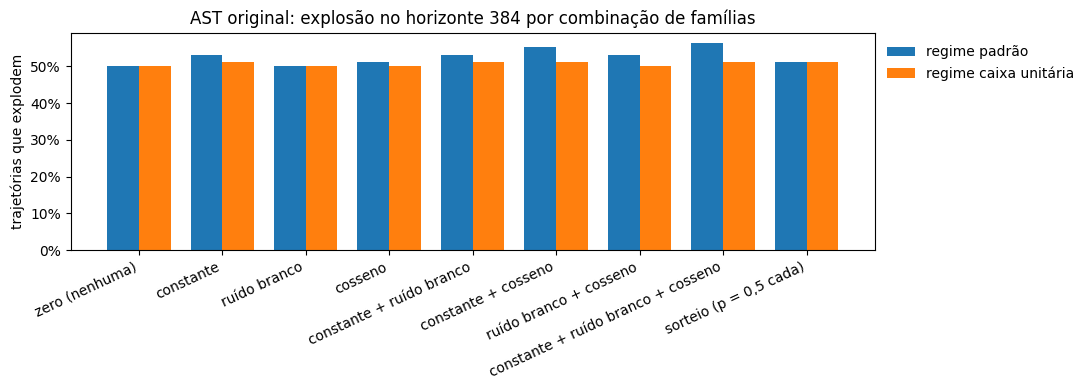

Explosões fora da AST original (todos os horizontes, regimes e casos): 0


In [5]:
part = summary[summary.method.eq("Original AST") & summary.horizon.eq(384)]
fig, ax = plt.subplots(figsize=(11, 4))
width = .38
x = np.arange(len(CASES))
for offset, regime in zip((-width / 2, width / 2), RANGES):
    values = part[part.regime.eq(regime)].set_index("case").reindex(CASES).explosions_rate
    ax.bar(x + offset, values, width, label=f"regime {regime}")
ax.set_xticks(x, CASES, rotation=25, ha="right")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_ylabel("trajetórias que explodem")
ax.set_title("AST original: explosão no horizonte 384 por combinação de famílias")
ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(1, 1)); fig.tight_layout(); plt.show()

others = summary[~summary.method.eq("Original AST")]
print("Explosões fora da AST original (todos os horizontes, regimes e casos):", int(others.explosions.sum()))

## Registro completo do experimento

A célula seguinte registra pergunta, hipótese, configuração, procedência, sementes,
métricas, resumo científico e comando de reprodução. Todos os resultados são
observações em horizontes finitos. Uma trajetória inválida permanece no denominador;
casos incompatíveis com o certificado são registrados como não executados.

In [6]:
SOURCE_PATHS = [
    "src/tsfmxai/evaluation/initialization.py",
    "src/tsfmxai/generators/initialization.py",
    "src/tsfmxai/generators/random_expression.py",
    "src/tsfmxai/generators/contraction.py",
    "src/tsfmxai/generators/shao_wu.py",
    "src/tsfmxai/generators/heaps.py",
    "src/tsfmxai/generators/stochastic.py",
    "src/tsfmxai/evaluation/stability.py",
]
final = summary[summary.horizon.eq(384)]
ast = final[final.method.eq("Original AST")]
def ast_range(regime):
    part = ast[ast.regime.eq(regime)].set_index("case").explosions_rate
    return (f"{part.min():.0%} ({part.idxmin()}) to {part.max():.0%} ({part.idxmax()}); "
            f"zero {part['zero (nenhuma)']:.0%}, mixture {part[MIXTURE]:.0%}")
jacobian_skipped = sorted(skipped_blocks[skipped_blocks.method.eq("Jacobian")].case.unique())
record = {
    "experiment_id": "04_random_family_aggregation",
    "status": "executed",
    "research_question": "Como a soma de famílias de inicialização sorteadas (constante, ruído branco, cosseno) afeta explosão e baixa amplitude nos quatro métodos finais?",
    "hypothesis": "Somar famílias altera o transiente, mas a explosão continua determinada principalmente pelo mecanismo, como nos notebooks 01–02.",
    "configuration": {
        "config": asdict(CONFIG),
        "families": {f: LABELS[f] for f in FAMILIES},
        "ranges": {regime: {key: list(value) for key, value in ranges.items()} for regime, ranges in RANGES.items()},
        "cases": {regime: [asdict(s) for s in specs] for regime, specs in SPECS.items()},
        "history_length": "required lag memory of each mechanism (illustrations use 16)",
        "noise_policy": "one explicit innovation stream per mechanism and trajectory; uniform bounded for Jacobian, Gaussian for other methods",
        "denominator_policy": "all attempted trajectories; laws whose conservative bound exceeds the Jacobian certified box are listed in skipped",
    },
    "seed_policy": {
        "mechanism_root_seed": CONFIG.mechanism_seed,
        "trajectory_root_seed": CONFIG.trajectory_seed,
        "mechanism": "derive_sample_seed(mechanism_seed, mechanism_index)",
        "initialization_noise_family": "SeedSequence([trajectory_seed, mechanism_index, trajectory_index]).spawn(3); the third stream drives sample_random_history",
        "pairing": "fixed draw order per channel, so family parameters are identical across combinations for the same trajectory",
        "illustration_seeds": [7, 100, 101, 102, 103, 2026],
        "mechanism_bank_reused_across_cases": True,
    },
    "provenance": {
        "git_head": subprocess.check_output(["git", "rev-parse", "HEAD"], cwd=ROOT, text=True).strip(),
        "dirty_worktree_at_execution": bool(subprocess.check_output(["git", "status", "--porcelain"], cwd=ROOT)),
        "python": sys.version,
        "platform": platform.platform(),
        "packages": {p: importlib.metadata.version(p) for p in ("numpy", "pandas", "matplotlib", "nbformat", "nbclient")},
        "source_sha256": {p: hashlib.sha256((ROOT / p).read_bytes()).hexdigest() for p in SOURCE_PATHS},
    },
    "metrics": {"summary": json.loads(summary.to_json(orient="records")),
                "skipped": json.loads(skipped_blocks.to_json(orient="records"))},
    "scientific_summary": (
        "Horizon 384. Original AST explosion, default regime: " + ast_range("padrão")
        + "; unit-box regime: " + ast_range("caixa unitária")
        + f". Jacobian, Shao-Wu and Heaps: {int(final[~final.method.eq('Original AST')].explosions.sum())} explosions over all cases."
        + f" Jacobian not executed (bound above radius 1) for: {', '.join(jacobian_skipped) or 'none'}."
        + " Rates depend on the sampled mechanisms and finite horizons."
    ),
    "limitations": "32 mechanisms per family and three paths per mechanism; finite horizons; the conservative sum bound excludes Jacobian cases whose actual draws could fit the box; no claim for coupled multiseries training systems.",
    "reproduction": "From repository root: python -m jupyter nbconvert --to notebook --execute experiments/time_series_initialization/final_methods/04_random_family_aggregation.ipynb --output 04_random_family_aggregation.ipynb --output-dir experiments/time_series_initialization/final_methods --ExecutePreprocessor.timeout=1800",
}
print(json.dumps(record, ensure_ascii=False, indent=2, default=lambda v: float(v) if isinstance(v, np.floating) else int(v) if isinstance(v, np.integer) else list(v)))

{
  "experiment_id": "04_random_family_aggregation",
  "status": "executed",
  "research_question": "Como a soma de famílias de inicialização sorteadas (constante, ruído branco, cosseno) afeta explosão e baixa amplitude nos quatro métodos finais?",
  "hypothesis": "Somar famílias altera o transiente, mas a explosão continua determinada principalmente pelo mecanismo, como nos notebooks 01–02.",
  "configuration": {
    "config": {
      "mechanisms": 32,
      "trajectories": 3,
      "mechanism_seed": 2026111001,
      "trajectory_seed": 2026111002,
      "horizons": [
        96,
        192,
        384
      ],
      "innovation_std": 0.05,
      "explosion_limit": 1000000.0,
      "near_zero_radius": 0.15,
      "tail_steps": 48,
      "flat_tolerance": 0.15,
      "window_steps": 24,
      "constant_value": 0.5,
      "uniform_radius": 1.0,
      "magnitude_scales": [
        0.0,
        0.1,
        0.5,
        1.0,
        2.0,
        4.0
      ],
      "forgetting_tolerance"